![Logo](images/1.png)

### 1. Экспортируем в ONNX две свои модели: LeNet из задания 1 и дообученный MobileNet из задания 2 

In [ ]:
# установка onnx
# %pip install onnx onnxruntime

In [24]:
from pathlib import Path

import torch
from torch import nn
from torchvision.models import mobilenet_v3_large

base_dir = Path("..")
output_dir = base_dir / "Task_3" / "hw3"
output_dir.mkdir(parents=True, exist_ok=True)


class LeNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Conv2d(6, 16, kernel_size=5),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 4 * 4, 120),
            nn.ReLU(),
            nn.Linear(120, 84),
            nn.ReLU(),
            nn.Linear(84, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


lenet = LeNet()
lenet.load_state_dict(torch.load(
    base_dir / "Task_1" / "lenet.pth",
    map_location="cpu",
    weights_only=True,
))
lenet.eval()

mobilenet = mobilenet_v3_large(weights=None)
mobilenet.classifier[3] = nn.Linear(1280, 102)
mobilenet.load_state_dict(torch.load(
    base_dir / "Task_2" / "mobilenet_v3.pth",
    map_location="cpu",
    weights_only=True,
))
mobilenet.eval()

with torch.inference_mode():
    for name, model, shape, classes in [
        ("LeNet", lenet, (1, 1, 28, 28), 10),
        ("MobileNetV3", mobilenet, (1, 3, 224, 224), 102),
    ]:
        output = model(torch.zeros(shape))
        assert output.shape == (1, classes), output.shape
        assert torch.isfinite(output).all()
        print(f"{name}: загружена, выход {tuple(output.shape)}")

print("Результаты задания будем сохранять в:", output_dir)

LeNet: загружена, выход (1, 10)
MobileNetV3: загружена, выход (1, 102)
Результаты задания будем сохранять в: ../Task_3/hw3


In [25]:
import json
import onnx

models = [
    (
        "lenet",
        lenet,
        (1, 1, 28, 28),
        {
            "resize": None,
            "to_tensor": "grayscale, float32, значения от 0 до 1",
            "normalize": None,
        },
    ),
    (
        "mobilenet",
        mobilenet,
        (1, 3, 224, 224),
        {
            "resize": [224, 224],
            "to_tensor": "RGB, float32, значения от 0 до 1",
            "normalize": {
                "mean": [0.485, 0.456, 0.406],
                "std": [0.229, 0.224, 0.225],
            },
        },
    ),
]

for name, model, shape, preprocessing in models:
    model.cpu().eval()
    path = output_dir / f"{name}_fp32.onnx"

    torch.onnx.export(
        model,
        torch.zeros(shape),
        str(path),
        input_names=["input"],
        output_names=["logits"],
        opset_version=17,
        dynamo=False,
    )

    graph = onnx.load(str(path))
    onnx.checker.check_model(graph)

    exported_shape = [
        dimension.dim_value
        for dimension in graph.graph.input[0].type.tensor_type.shape.dim
    ]
    assert exported_shape == list(shape), exported_shape
    assert next(
        item.version for item in graph.opset_import if item.domain == ""
    ) == 17

    metadata = {
        "input_name": "input",
        "input_shape": list(shape),
        "input_dtype": "float32",
        "output_name": "logits",
        "preprocessing": preprocessing,
    }
    path.with_suffix(".json").write_text(
        json.dumps(metadata, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

    print(f"{path.name}: проверка ONNX пройдена, вход {exported_shape}")

/tmp/ipykernel_66817/3856939319.py:34: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


lenet_fp32.onnx: проверка ONNX пройдена, вход [1, 1, 28, 28]
mobilenet_fp32.onnx: проверка ONNX пройдена, вход [1, 3, 224, 224]


In [26]:
import json
import numpy as np
import onnxruntime as ort
from torchvision import datasets, transforms

mnist_val = datasets.MNIST(
    root=str(base_dir / "Task_1" / "MNIST"),
    train=False,
    download=False,
    transform=transforms.ToTensor(),
)

flowers_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

flowers_val = datasets.Flowers102(
    root=str(base_dir / "Task_2" / "Flowers"),
    split="val",
    download=False,
    transform=flowers_transform,
)

export_comparison = {}

for name, model, dataset in [
    ("lenet", lenet, mnist_val),
    ("mobilenet", mobilenet, flowers_val),
]:
    options = ort.SessionOptions()
    options.intra_op_num_threads = 1

    session = ort.InferenceSession(
        str(output_dir / f"{name}_fp32.onnx"),
        sess_options=options,
        providers=["CPUExecutionProvider"],
    )
    input_name = session.get_inputs()[0].name

    model.cpu().eval()
    max_abs_diff = 0.0
    matched = 0
    torch_correct = 0
    onnx_correct = 0

    assert len(dataset) >= 100

    with torch.inference_mode():
        for index in range(100):
            image, label = dataset[index]
            x = image.unsqueeze(0).contiguous()

            torch_output = model(x).numpy()
            onnx_output = session.run(None, {input_name: x.numpy()})[0]

            assert torch_output.shape == onnx_output.shape
            assert np.isfinite(torch_output).all()
            assert np.isfinite(onnx_output).all()

            difference = np.max(np.abs(torch_output - onnx_output))
            max_abs_diff = max(max_abs_diff, float(difference))

            torch_prediction = int(torch_output.argmax(axis=1)[0])
            onnx_prediction = int(onnx_output.argmax(axis=1)[0])

            matched += torch_prediction == onnx_prediction
            torch_correct += torch_prediction == label
            onnx_correct += onnx_prediction == label

    export_comparison[name] = {
        "n_samples": 100,
        "max_abs_diff": max_abs_diff,
        "prediction_agreement": matched / 100,
        "torch_accuracy_100": torch_correct / 100,
        "onnx_accuracy_100": onnx_correct / 100,
    }

    print(f"\n{name}")
    print(f"Максимальное расхождение выходов: {max_abs_diff:.8g}")
    print(f"Совпадение предсказаний: {matched}/100")
    print(f"Accuracy PyTorch: {torch_correct / 100:.2%}")
    print(f"Accuracy ONNX:    {onnx_correct / 100:.2%}")

results_path = output_dir / "export_comparison.json"
results_path.write_text(
    json.dumps(export_comparison, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print("\nРезультаты сохранены:", results_path)


lenet
Максимальное расхождение выходов: 4.7683716e-06
Совпадение предсказаний: 100/100
Accuracy PyTorch: 100.00%
Accuracy ONNX:    100.00%

mobilenet
Максимальное расхождение выходов: 9.5963478e-06
Совпадение предсказаний: 100/100
Accuracy PyTorch: 77.00%
Accuracy ONNX:    77.00%

Результаты сохранены: ../Task_3/hw3/export_comparison.json


### 2. Квантуем обе модели в int8

#### Как работает квантизация

```text
Модель FP32 + 64 картинки из train
               │
               ▼
          КАЛИБРОВКА
   Измеряем диапазоны чисел
        на выходах слоёв
               │
               ▼
         КВАНТИЗАЦИЯ
   Заменяем float32 на int8
   с округлением и масштабом
               │
               ▼
          Модель INT8
   Меньше памяти, может работать быстрее
   Возможна небольшая потеря точности
```

**Пример округления:** при масштабе 0.01 число `0.237`
кодируется целым `24`, которое соответствует `0.24`.

Модель **не переобучаем**. Входные картинки остаются `float32`.

| Модель | FP32 | INT8 | Уменьшение |
|---|---:|---:|---:|
| LeNet | 0.172 MiB | 0.057 MiB | 3.03× |
| MobileNetV3 | 16.518 MiB | 4.615 MiB | 3.58× |

Точность и ускорение после квантизации ещё предстоит измерить.

In [27]:
import tempfile

from onnxruntime.quantization import (
    CalibrationDataReader,
    CalibrationMethod,
    QuantFormat,
    QuantType,
    quantize_static,
)
from onnxruntime.quantization.shape_inference import quant_pre_process

mnist_calibration = datasets.MNIST(
    root=str(base_dir / "Task_1" / "MNIST"),
    train=True,
    download=False,
    transform=transforms.ToTensor(),
)

flowers_calibration = datasets.Flowers102(
    root=str(base_dir / "Task_2" / "Flowers"),
    split="train",
    download=False,
    # Предобработка как при валидации, без случайных аугментаций.
    transform=flowers_transform,
)


class CalibrationReader(CalibrationDataReader):
    def __init__(self, dataset, indices, input_name):
        self.samples = iter(
            {
                input_name: np.ascontiguousarray(
                    dataset[int(index)][0].unsqueeze(0).numpy(),
                    dtype=np.float32,
                )
            }
            for index in indices
        )

    def get_next(self):
        return next(self.samples, None)


for name, dataset in [
    ("lenet", mnist_calibration),
    ("mobilenet", flowers_calibration),
]:
    fp32_path = output_dir / f"{name}_fp32.onnx"
    int8_path = output_dir / f"{name}_int8.onnx"

    # Случайные, но воспроизводимые 64 объекта из train.
    indices = np.random.default_rng(42).choice(
        len(dataset), size=64, replace=False
    )
    input_name = onnx.load(str(fp32_path)).graph.input[0].name
    reader = CalibrationReader(dataset, indices, input_name)

    with tempfile.TemporaryDirectory() as temporary_dir:
        prepared_path = str(Path(temporary_dir) / "prepared.onnx")

        quant_pre_process(
            input_model=str(fp32_path),
            output_model_path=prepared_path,
        )

        quantize_static(
            model_input=prepared_path,
            model_output=str(int8_path),
            calibration_data_reader=reader,
            quant_format=QuantFormat.QDQ,
            activation_type=QuantType.QInt8,
            weight_type=QuantType.QInt8,
            per_channel=True,
            calibrate_method=CalibrationMethod.MinMax,
        )

    graph = onnx.load(str(int8_path))
    onnx.checker.check_model(graph)
    assert any(
        tensor.data_type == onnx.TensorProto.INT8
        for tensor in graph.graph.initializer
    ), "В модели не обнаружены int8-веса"

    # Проверяем, что модель действительно запускается.
    options = ort.SessionOptions()
    options.intra_op_num_threads = 1
    session = ort.InferenceSession(
        str(int8_path),
        sess_options=options,
        providers=["CPUExecutionProvider"],
    )
    sample = dataset[int(indices[0])][0].unsqueeze(0).numpy()
    output = session.run(None, {input_name: sample})[0]
    assert np.isfinite(output).all()

    metadata = json.loads(
        fp32_path.with_suffix(".json").read_text(encoding="utf-8")
    )
    metadata["quantization"] = {
        "format": "QDQ",
        "calibration_split": "train",
        "calibration_indices": indices.tolist(),
        "method": "MinMax",
        "per_channel": True,
    }
    int8_path.with_suffix(".json").write_text(
        json.dumps(metadata, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

    fp32_size = fp32_path.stat().st_size
    int8_size = int8_path.stat().st_size

    print(f"\n{name}: int8 создана и запускается")
    print(f"FP32: {fp32_size / 1024**2:.3f} MiB")
    print(f"INT8: {int8_size / 1024**2:.3f} MiB")
    print(f"Уменьшение файла: {fp32_size / int8_size:.2f} раза")


lenet: int8 создана и запускается
FP32: 0.172 MiB
INT8: 0.057 MiB
Уменьшение файла: 3.03 раза

mobilenet: int8 создана и запускается
FP32: 16.518 MiB
INT8: 4.615 MiB
Уменьшение файла: 3.58 раза


In [28]:
import time
import numpy as np
import onnxruntime as ort
from IPython.display import Markdown, display

results = []

for name, dataset, model in [
    ("lenet", mnist_val, lenet),
    ("mobilenet", flowers_val, mobilenet),
]:
    # Эти же входы позже используем на Raspberry Pi.
    x64 = np.stack([dataset[i][0].numpy() for i in range(64)])
    x64 = np.ascontiguousarray(x64, dtype=np.float32)
    y64 = np.array([dataset[i][1] for i in range(64)], dtype=np.int64)

    assert x64.ndim == 4
    assert np.isfinite(x64).all()

    npz_name = "mnist_val64.npz" if name == "lenet" else "flowers_val64.npz"
    np.savez(output_dir / npz_name, x=x64, y=y64)

    for precision in ["fp32", "int8"]:
        model_path = output_dir / f"{name}_{precision}.onnx"

        for threads in [1, 4]:
            options = ort.SessionOptions()
            options.intra_op_num_threads = threads
            options.inter_op_num_threads = 1
            options.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL

            session = ort.InferenceSession(
                str(model_path),
                sess_options=options,
                providers=["CPUExecutionProvider"],
            )
            input_name = session.get_inputs()[0].name

            # Полную точность считаем один раз для каждого файла модели.
            if threads == 1:
                print(
                    f"{name} {precision}: "
                    f"проверка на {len(dataset)} объектах...",
                    flush=True,
                )
                correct = 0
                predictions64 = []

                for i in range(len(dataset)):
                    image, label = dataset[i]
                    x = np.ascontiguousarray(
                        image.unsqueeze(0).numpy(), dtype=np.float32
                    )
                    logits = session.run(None, {input_name: x})[0]
                    assert np.isfinite(logits).all()

                    prediction = int(logits.argmax(axis=1)[0])
                    correct += prediction == label

                    if i < 64:
                        predictions64.append(prediction)

                accuracy = correct / len(dataset)
                np.save(
                    output_dir / f"{name}_{precision}_server.npy",
                    np.array(predictions64, dtype=np.int64),
                )

            # Прогрев: создание сессии и первые вызовы в замер не входят.
            for i in range(5):
                session.run(None, {input_name: x64[i:i + 1]})

            # 5 проходов по 64 объектам, каждый вызов с batch=1.
            inputs = [
                {input_name: x64[i:i + 1]}
                for i in range(64)
            ]
            elapsed_ms = []

            for _ in range(5):
                for feed in inputs:
                    start = time.perf_counter_ns()
                    session.run(None, feed)
                    elapsed_ms.append(
                        (time.perf_counter_ns() - start) / 1e6
                    )

            row = {
                "model": name,
                "parameters": sum(p.numel() for p in model.parameters()),
                "format": precision,
                "device": "server CPU",
                "threads": threads,
                "accuracy": accuracy,
                "validation_count": len(dataset),
                "p50_ms": float(np.percentile(elapsed_ms, 50)),
                "p95_ms": float(np.percentile(elapsed_ms, 95)),
                "size_bytes": model_path.stat().st_size,
                "timed_runs": len(elapsed_ms),
            }
            results.append(row)

            print(
                f"  {precision}, {threads} поток(а): "
                f"accuracy={accuracy:.2%}, "
                f"p50={row['p50_ms']:.3f} мс, "
                f"p95={row['p95_ms']:.3f} мс",
                flush=True,
            )
            del session

    # Сохраняем результаты после каждой модели.
    (output_dir / "server_results.json").write_text(
        json.dumps(results, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

table = [
    "| Модель | Формат | Потоков | Accuracy | p50, мс | p95, мс | MiB |",
    "|---|---|---:|---:|---:|---:|---:|",
]
for row in results:
    table.append(
        f"| {row['model']} | {row['format']} | {row['threads']} "
        f"| {row['accuracy']:.2%} | {row['p50_ms']:.3f} "
        f"| {row['p95_ms']:.3f} | {row['size_bytes'] / 1024**2:.3f} |"
    )
display(Markdown("\n".join(table)))

for name in ["lenet", "mobilenet"]:
    rows = {
        row["format"]: row
        for row in results
        if row["model"] == name and row["threads"] == 1
    }
    drop = (rows["fp32"]["accuracy"] - rows["int8"]["accuracy"]) * 100
    print(f"{name}: падение точности после квантизации = {drop:+.2f} п.п.")

lenet fp32: проверка на 10000 объектах...


  fp32, 1 поток(а): accuracy=98.43%, p50=0.032 мс, p95=0.037 мс
  fp32, 4 поток(а): accuracy=98.43%, p50=0.035 мс, p95=0.037 мс
lenet int8: проверка на 10000 объектах...
  int8, 1 поток(а): accuracy=98.46%, p50=0.075 мс, p95=0.080 мс
  int8, 4 поток(а): accuracy=98.46%, p50=0.074 мс, p95=0.096 мс
mobilenet fp32: проверка на 1020 объектах...
  fp32, 1 поток(а): accuracy=79.02%, p50=5.403 мс, p95=5.513 мс
  fp32, 4 поток(а): accuracy=79.02%, p50=2.002 мс, p95=2.048 мс
mobilenet int8: проверка на 1020 объектах...
  int8, 1 поток(а): accuracy=38.24%, p50=19.063 мс, p95=19.631 мс
  int8, 4 поток(а): accuracy=38.24%, p50=12.291 мс, p95=12.700 мс


| Модель | Формат | Потоков | Accuracy | p50, мс | p95, мс | MiB |
|---|---|---:|---:|---:|---:|---:|
| lenet | fp32 | 1 | 98.43% | 0.032 | 0.037 | 0.172 |
| lenet | fp32 | 4 | 98.43% | 0.035 | 0.037 | 0.172 |
| lenet | int8 | 1 | 98.46% | 0.075 | 0.080 | 0.057 |
| lenet | int8 | 4 | 98.46% | 0.074 | 0.096 | 0.057 |
| mobilenet | fp32 | 1 | 79.02% | 5.403 | 5.513 | 16.518 |
| mobilenet | fp32 | 4 | 79.02% | 2.002 | 2.048 | 16.518 |
| mobilenet | int8 | 1 | 38.24% | 19.063 | 19.631 | 4.615 |
| mobilenet | int8 | 4 | 38.24% | 12.291 | 12.700 | 4.615 |

lenet: падение точности после квантизации = -0.03 п.п.
mobilenet: падение точности после квантизации = +40.78 п.п.


In [11]:
candidate_path = output_dir / "mobilenet_int8_mixed.onnx"
indices = np.random.default_rng(42).choice(
    len(flowers_calibration), size=64, replace=False
)

options = ort.SessionOptions()
options.intra_op_num_threads = 1
options.inter_op_num_threads = 1

with tempfile.TemporaryDirectory() as temporary_dir:
    prepared_path = str(Path(temporary_dir) / "prepared.onnx")

    quant_pre_process(
        input_model=str(output_dir / "mobilenet_fp32.onnx"),
        output_model_path=prepared_path,
    )

    graph = onnx.load(str(prepared_path)).graph

    excluded_nodes = [
        node.name
        for node in graph.node
        if node.op_type == "Conv"
        and any(
            attribute.name == "group" and attribute.i > 1
            for attribute in node.attribute
        )
    ]

    assert excluded_nodes, "Depthwise-свёртки не найдены"
    print(f"Оставляем в FP32 {len(excluded_nodes)} depthwise-свёрток")

    # Сначала проверяем, не испортила ли модель сама подготовка графа.
    original = ort.InferenceSession(
        str(output_dir / "mobilenet_fp32.onnx"),
        sess_options=options,
        providers=["CPUExecutionProvider"],
    )
    prepared = ort.InferenceSession(
        prepared_path,
        sess_options=options,
        providers=["CPUExecutionProvider"],
    )

    max_difference = 0.0
    matches = 0

    for i in range(100):
        x = flowers_val[i][0].unsqueeze(0).numpy()
        a = original.run(None, {"input": x})[0]
        b = prepared.run(None, {"input": x})[0]
        assert np.isfinite(a).all() and np.isfinite(b).all()

        max_difference = max(
            max_difference, float(np.max(np.abs(a - b)))
        )
        matches += int(a.argmax() == b.argmax())

    print("Подготовка FP32-графа:")
    print("Максимальное расхождение:", max_difference)
    print(f"Совпадение предсказаний: {matches}/100")

    del original, prepared

    quantize_static(
        model_input=prepared_path,
        model_output=str(candidate_path),
        calibration_data_reader=CalibrationReader(
            flowers_calibration, indices, "input"
        ),
        quant_format=QuantFormat.QDQ,
        activation_type=QuantType.QInt8,
        weight_type=QuantType.QInt8,
        per_channel=True,
        calibrate_method=CalibrationMethod.MinMax,
        op_types_to_quantize=["Conv", "Gemm", "MatMul"],
        nodes_to_exclude=excluded_nodes,
    )

onnx.checker.check_model(onnx.load(str(candidate_path)))

session = ort.InferenceSession(
    str(candidate_path),
    sess_options=options,
    providers=["CPUExecutionProvider"],
)

correct = 0

for image, label in flowers_val:
    x = image.unsqueeze(0).numpy()
    logits = session.run(None, {"input": x})[0]
    assert np.isfinite(logits).all()
    correct += int(logits.argmax(axis=1)[0]) == label

accuracy = correct / len(flowers_val)

# Проверяем скорость на тех же первых 64 объектах.
feeds = [
    {"input": flowers_val[i][0].unsqueeze(0).numpy()}
    for i in range(64)
]

for feed in feeds[:5]:
    session.run(None, feed)

times_ms = []
for _ in range(5):
    for feed in feeds:
        start = time.perf_counter_ns()
        session.run(None, feed)
        times_ms.append((time.perf_counter_ns() - start) / 1e6)

print("\nНовый вариант INT8, 1 поток:")
print(f"Accuracy: {accuracy:.2%}")
print(f"p50: {np.percentile(times_ms, 50):.3f} мс")
print(f"p95: {np.percentile(times_ms, 95):.3f} мс")
print(f"Размер: {candidate_path.stat().st_size / 1024**2:.3f} MiB")

del session

Оставляем в FP32 15 depthwise-свёрток
Подготовка FP32-графа:
Максимальное расхождение: 0.0
Совпадение предсказаний: 100/100

Новый вариант INT8, 1 поток:
Accuracy: 72.94%
p50: 9.787 мс
p95: 9.986 мс
Размер: 4.768 MiB


| Вариант MobileNet | Accuracy | p50, 1 поток | Размер |
|---|---:|---:|---:|
| FP32 | 79,02% | 5,445 мс | 16,518 MiB |
| Исходный INT8 | 38,24% | 19,351 мс | 4,615 MiB |
| Смешанный, depthwise в FP32 | 72,94% | 9,787 мс | 4,768 MiB |


Если все перевести в INT8 то качесвто очень проседает из-за depthwise-свёрток. Если их оставить в FP32, то качество упадет на 6 пп, но размер уменьшится в 4 раза.

### 3. Переносим модели на плату

In [ ]:
# scp -P 11111 \
#   lenet_fp32.onnx lenet_int8.onnx \
#   mobilenet_fp32.onnx mobilenet_int8.onnx \
#   mobilenet_int8_mixed.onnx \
#   mnist_val64.npz flowers_val64.npz \
#   student03@81.5.110.19:~/hw3/

In [ ]:
# тестовый замер. нагрузка на плату низкая

# (venv) student03@raspberrypi:~/hw3 $ uptime | tee lenet_fp32_uptime.txt
#  19:34:21 up 14 days, 19:31,  4 users,  load average: 0.06, 0.01, 0.00
# (venv) student03@raspberrypi:~/hw3 $ python3 classify_onnx.py \
#   lenet_fp32.onnx mnist_val64.npz \
#   --threads 1,4 \
#   --save-preds lenet_fp32_pi.npy \
#   | tee lenet_fp32_pi.log
# машина: aarch64, onnxruntime 1.29.0
# модель: lenet_fp32.onnx, 0.18 МБ; примеров: 64, форма входа (1, 28, 28)

# потоков  точность   p50, мс   p95, мс  примеров/с
#       1     1.000      0.07      0.08     13775.4
#       4     1.000      0.06      0.07     17059.0

# предсказания сохранены: lenet_fp32_pi.npy

команда:


```bash 
for model in lenet_int8 mobilenet_fp32 mobilenet_int8 mobilenet_int8_mixed
do
  if [ "$model" = "lenet_int8" ]; then
    data=mnist_val64.npz
  else
    data=flowers_val64.npz
  fi

  uptime | tee "${model}_uptime.txt"

  python3 classify_onnx.py \
    "${model}.onnx" "$data" \
    --threads 1,4 \
    --save-preds "${model}_pi.npy" \
    2>&1 | tee "${model}_pi.log"
done
```

Результат: На Raspberry Pi обычный INT8 MobileNet ускорился относительно FP32: в 2,23 раза на одном потоке и 1,78 раза на четырёх, но точность заметно снизилась.

| Модель | Accuracy на 64 объектах | p50, 1 поток | p50, 4 потока |
|---|---:|---:|---:|
| LeNet FP32 | 100% | 0,07 мс | 0,06 мс |
| LeNet INT8 | 100% | 0,11 мс | 0,10 мс |
| MobileNet FP32 | 67,2% | 31,05 мс | 14,27 мс |
| MobileNet INT8 | 29,7% | 13,90 мс | 8,00 мс |
| MobileNet смешанный | 67,2% | 27,26 мс | 15,19 мс |

In [11]:
comparison = {}

for name in [
    "lenet_fp32",
    "lenet_int8",
    "mobilenet_fp32",
    "mobilenet_int8",
    "mobilenet_int8_mixed",
]:
    dataset_file = (
        "mnist_val64.npz" if name.startswith("lenet")
        else "flowers_val64.npz"
    )

    with np.load(output_dir / dataset_file) as data:
        x = data["x"]
        y = data["y"]

    assert x.dtype == np.float32
    assert len(x) == len(y) == 64

    options = ort.SessionOptions()
    options.intra_op_num_threads = 1
    options.inter_op_num_threads = 1

    session = ort.InferenceSession(
        str(output_dir / f"{name}.onnx"),
        sess_options=options,
        providers=["CPUExecutionProvider"],
    )
    input_name = session.get_inputs()[0].name

    server_predictions = []
    for i in range(len(x)):
        logits = session.run(None, {input_name: x[i:i + 1]})[0]
        assert np.isfinite(logits).all()
        server_predictions.append(int(logits.argmax(axis=1)[0]))

    server_predictions = np.array(server_predictions, dtype=np.int64)
    pi_predictions = np.load(output_dir / f"{name}_pi.npy")

    assert pi_predictions.shape == server_predictions.shape, (
        f"{name}: форма файла платы {pi_predictions.shape}, "
        f"ожидалась {server_predictions.shape}"
    )

    differences = np.flatnonzero(server_predictions != pi_predictions)

    comparison[name] = {
        "agreement": float(np.mean(server_predictions == pi_predictions)),
        "server_accuracy_64": float(np.mean(server_predictions == y)),
        "pi_accuracy_64": float(np.mean(pi_predictions == y)),
        "different_indices": differences.tolist(),
    }

    np.save(output_dir / f"{name}_server.npy", server_predictions)

    row = comparison[name]
    print(
        f"{name}: совпало {64 - len(differences)}/64 | "
        f"сервер {row['server_accuracy_64']:.2%} | "
        f"Pi {row['pi_accuracy_64']:.2%}"
    )
    if len(differences):
        print("  Индексы несовпадений:", differences.tolist())

    del session

(output_dir / "server_pi_comparison.json").write_text(
    json.dumps(comparison, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

lenet_fp32: совпало 64/64 | сервер 100.00% | Pi 100.00%
lenet_int8: совпало 64/64 | сервер 100.00% | Pi 100.00%
mobilenet_fp32: совпало 64/64 | сервер 67.19% | Pi 67.19%
mobilenet_int8: совпало 43/64 | сервер 31.25% | Pi 29.69%
  Индексы несовпадений: [0, 3, 4, 9, 16, 17, 21, 23, 27, 29, 30, 31, 38, 39, 43, 44, 46, 48, 50, 51, 57]
mobilenet_int8_mixed: совпало 59/64 | сервер 64.06% | Pi 67.19%
  Индексы несовпадений: [4, 22, 29, 35, 60]


976

Интересный момент, что предсказания в fp32 версиях локально и на RP совпали, а вот INT8 - нет. Перепровреил по хэшам данных и моделей - одно и тоже там и там. Значит различия появились из-за среды исполнения.

В mobilenet_int8_mixed даже выросла точность на RP Pi)

### 4. Шкала тяжеловесности.

#### Шкала тяжеловесности моделей на Raspberry Pi 5

Измерены готовые MobileNetV2 и VGG16 со стенда в форматах FP32 и INT8.
Каждый запуск обрабатывает один объект.

Условия измерения:
- архитектура: aarch64;
- ONNX Runtime: 1.29.0;
- число потоков: 1 и 4;
- число измерительных итераций: 10;
- load average перед замерами: 0.44 / 0.15 / 0.05 для MobileNetV2
  и 0.48 / 0.16 / 0.06 для VGG16.

##### Результаты

| Модель | Формат | Потоков | p50, мс | p95, мс | Размер, МБ |
|---|---|---:|---:|---:|---:|
| MobileNetV2 | FP32 | 1 | 33.7 | 33.7 | 14.0 |
| MobileNetV2 | FP32 | 4 | 14.4 | 14.6 | 14.0 |
| MobileNetV2 | INT8 | 1 | 14.3 | 14.4 | 3.9 |
| MobileNetV2 | INT8 | 4 | 6.6 | 6.6 | 3.9 |
| VGG16 | FP32 | 1 | 1030.2 | 1030.8 | 553.4 |
| VGG16 | FP32 | 4 | 378.3 | 395.8 | 553.4 |
| VGG16 | INT8 | 1 | 267.5 | 267.6 | 138.6 |
| VGG16 | INT8 | 4 | 91.6 | 93.9 | 138.6 |

p50 — медианная задержка. p95 — задержка, в которую укладываются
95% измерений. Размеры приведены в десятичных МБ, как в выводе стенда.
Точность этих готовых моделей в данном эксперименте не оценивалась.

##### Эффект квантизации и числа потоков

Ускорение рассчитано как отношение медианных задержек:
время до изменения / время после изменения.

| Модель | Ускорение от INT8, 1 поток | Ускорение от INT8, 4 потока | Ускорение от 4 потоков, FP32 | Ускорение от 4 потоков, INT8 |
|---|---:|---:|---:|---:|
| MobileNetV2 | 2.36× | 2.18× | 2.34× | 2.17× |
| VGG16 | 3.85× | 4.13× | 2.72× | 2.92× |

##### Выводы

Квантизация ускорила обе модели. Наибольший выигрыш получен для VGG16:
в четыре потока её медианная задержка уменьшилась с 378.3 до 91.6 мс.

Переход с одного потока на четыре дал ускорение от 2.17 до 2.92 раза.
Линейного ускорения в четыре раза не получилось: часть работы
не распараллеливается, а потоки используют общую память и требуют координации.

В FP32 VGG16 медленнее MobileNetV2 в 30.6 раза при одном потоке
и в 26.3 раза при четырёх. В INT8 разрыв сокращается до 18.7 и 13.9 раза.

Эти замеры показывают эффект настроек, но сами по себе не позволяют
однозначно разделить ограничения арифметики, памяти и накладных расходов.
Для оценки устойчивости p95 десяти итераций недостаточно.

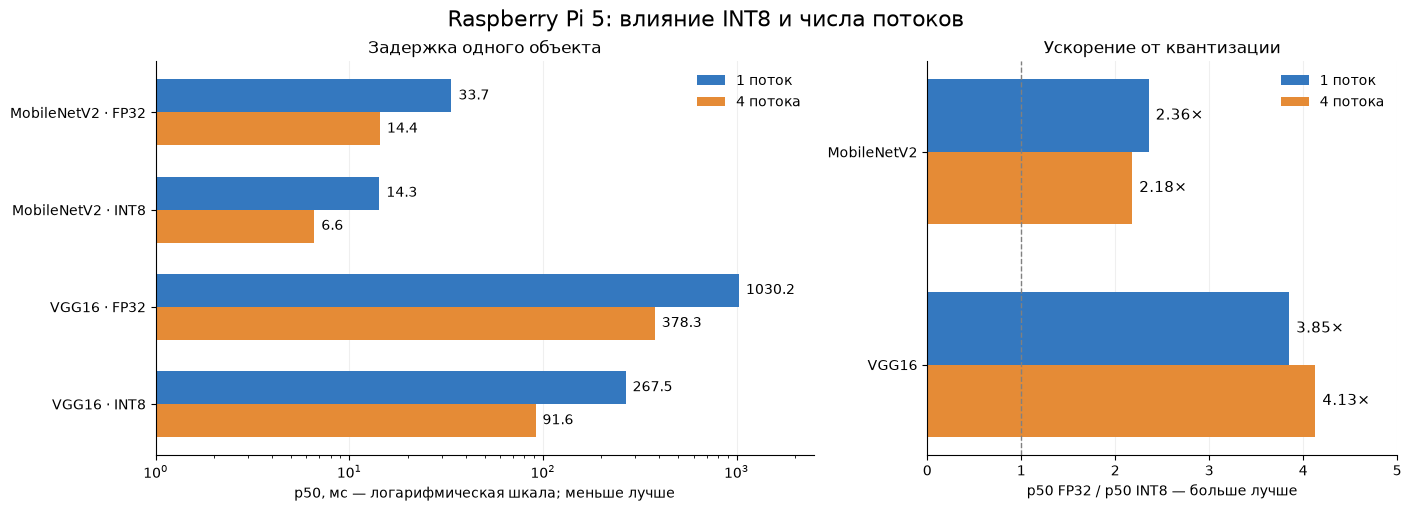

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# p50 из вывода стенда, мс.
labels = [
    "MobileNetV2 · FP32",
    "MobileNetV2 · INT8",
    "VGG16 · FP32",
    "VGG16 · INT8",
]
latency_1 = np.array([33.7, 14.3, 1030.2, 267.5])
latency_4 = np.array([14.4, 6.6, 378.3, 91.6])

assert np.all(latency_1 > 0) and np.all(latency_4 > 0)

colors = ["#3478BF", "#E58B36"]
height = 0.34

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5),
    gridspec_kw={"width_ratios": [1.4, 1]},
    constrained_layout=True,
)
fig.suptitle("Raspberry Pi 5: влияние INT8 и числа потоков", fontsize=16)

# Слева — абсолютная задержка.
ax = axes[0]
y = np.arange(len(labels))

for offset, values, color, label in [
    (-height / 2, latency_1, colors[0], "1 поток"),
    (height / 2, latency_4, colors[1], "4 потока"),
]:
    bars = ax.barh(
        y + offset, values, height=height,
        color=color, label=label,
    )
    ax.bar_label(
        bars, labels=[f"{v:.1f}" for v in values],
        padding=5, fontsize=10,
    )

ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlim(1, 2500)
ax.set_xlabel("p50, мс — логарифмическая шкала; меньше лучше")
ax.set_title("Задержка одного объекта")
ax.legend(frameon=False)
ax.grid(axis="x", which="major", alpha=0.2)
ax.set_axisbelow(True)

# Справа — ускорение от квантизации при одинаковом числе потоков.
ax = axes[1]
models = ["MobileNetV2", "VGG16"]
y = np.arange(len(models))

speedup_1 = latency_1[[0, 2]] / latency_1[[1, 3]]
speedup_4 = latency_4[[0, 2]] / latency_4[[1, 3]]

for offset, values, color, label in [
    (-height / 2, speedup_1, colors[0], "1 поток"),
    (height / 2, speedup_4, colors[1], "4 потока"),
]:
    bars = ax.barh(
        y + offset, values, height=height,
        color=color, label=label,
    )
    ax.bar_label(
        bars, labels=[f"{v:.2f}×" for v in values],
        padding=5, fontsize=11,
    )

ax.set_yticks(y, models)
ax.invert_yaxis()
ax.axvline(1, color="gray", linestyle="--", linewidth=1)
ax.set_xlim(0, 5)
ax.set_xlabel("p50 FP32 / p50 INT8 — больше лучше")
ax.set_title("Ускорение от квантизации")
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.show()

In [14]:
import subprocess
import sys

reference_dir = output_dir / "reference_models"

for model_name in ["mobilenet_v2", "vgg16"]:
    script = reference_dir / "bench_onnx.py"
    fp32 = reference_dir / f"{model_name}_fp32.onnx"
    int8 = reference_dir / f"{model_name}_int8.onnx"

    for path in [script, fp32, int8]:
        assert path.is_file(), f"Не найден файл: {path}"

    print(f"\nЗамер {model_name} на CPU сервера:", flush=True)

    completed = subprocess.run(
        [
            sys.executable, str(script),
            str(fp32), str(int8),
            "--threads", "1,4",
            "--iterations", "10",
        ],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    )

    print(completed.stdout)
    (output_dir / f"{model_name}_server.log").write_text(
        completed.stdout, encoding="utf-8"
    )
    completed.check_returncode()


Замер mobilenet_v2 на CPU сервера:
машина: x86_64, onnxruntime 1.31.0
провайдеры: ['AzureExecutionProvider', 'CPUExecutionProvider']

модель                             потоков   p50, мс   p95, мс  кадров/с
mobilenet_v2_fp32.onnx (14.0 МБ)         1       6.8       6.9     146.2
mobilenet_v2_fp32.onnx (14.0 МБ)         4       2.1       2.1     477.6
mobilenet_v2_int8.onnx (3.9 МБ)          1       3.8       3.8     264.0
mobilenet_v2_int8.onnx (3.9 МБ)          4       1.4       1.4     708.5


Замер vgg16 на CPU сервера:
машина: x86_64, onnxruntime 1.31.0
провайдеры: ['AzureExecutionProvider', 'CPUExecutionProvider']

модель                             потоков   p50, мс   p95, мс  кадров/с
vgg16_fp32.onnx (553.4 МБ)               1     249.5     287.0       4.0
vgg16_fp32.onnx (553.4 МБ)               4      63.7      64.9      15.7
vgg16_int8.onnx (138.6 МБ)               1      63.5      64.0      15.7
vgg16_int8.onnx (138.6 МБ)               4      17.9      17.9      55.9



#### Сравнение Raspberry Pi 5 и учебного сервера

На обоих устройствах использованы одинаковые файлы моделей и скрипт
стенда, batch=1, 10 измерительных итераций.

- Raspberry Pi: aarch64, ONNX Runtime 1.29.0.
- Сервер: x86_64, ONNX Runtime 1.31.0.

##### Задержка одного объекта

Коэффициент замедления рассчитан как p50 Raspberry Pi / p50 сервера.

| Модель | Формат | Потоков | Сервер p50, мс | Pi p50, мс | Pi медленнее |
|---|---|---:|---:|---:|---:|
| MobileNetV2 | FP32 | 1 | 6.8 | 33.7 | 4.96× |
| MobileNetV2 | FP32 | 4 | 2.1 | 14.4 | 6.86× |
| MobileNetV2 | INT8 | 1 | 3.8 | 14.3 | 3.76× |
| MobileNetV2 | INT8 | 4 | 1.4 | 6.6 | 4.71× |
| VGG16 | FP32 | 1 | 249.5 | 1030.2 | 4.13× |
| VGG16 | FP32 | 4 | 63.7 | 378.3 | 5.94× |
| VGG16 | INT8 | 1 | 63.5 | 267.5 | 4.21× |
| VGG16 | INT8 | 4 | 17.9 | 91.6 | 5.12× |

##### Выводы

Единого коэффициента перехода от сервера к Raspberry Pi нет.
Например, в четыре потока разрыв составляет 6.86 раза для MobileNetV2
FP32 и 5.94 раза для VGG16 FP32.

Разница зависит от структуры модели, эффективности вычислительных
ядер, работы с памятью и масштабирования по потокам. Версии ONNX Runtime
тоже различаются, поэтому эксперимент сравнивает две среды исполнения
целиком, а не только процессоры.

INT8 ускорил обе готовые модели на обоих устройствах.
Для VGG16 ускорение составляет примерно четыре раза:
на сервере — 3.93× и 3.56×, на Raspberry Pi — 3.85× и 4.13×
при одном и четырёх потоках соответственно.

Малое число итераций ограничивает точность оценки хвостов распределения.
В частности, у VGG16 FP32 на сервере в один поток p95 = 287.0 мс
при p50 = 249.5 мс: отдельные вызовы заметно медленнее медианы.

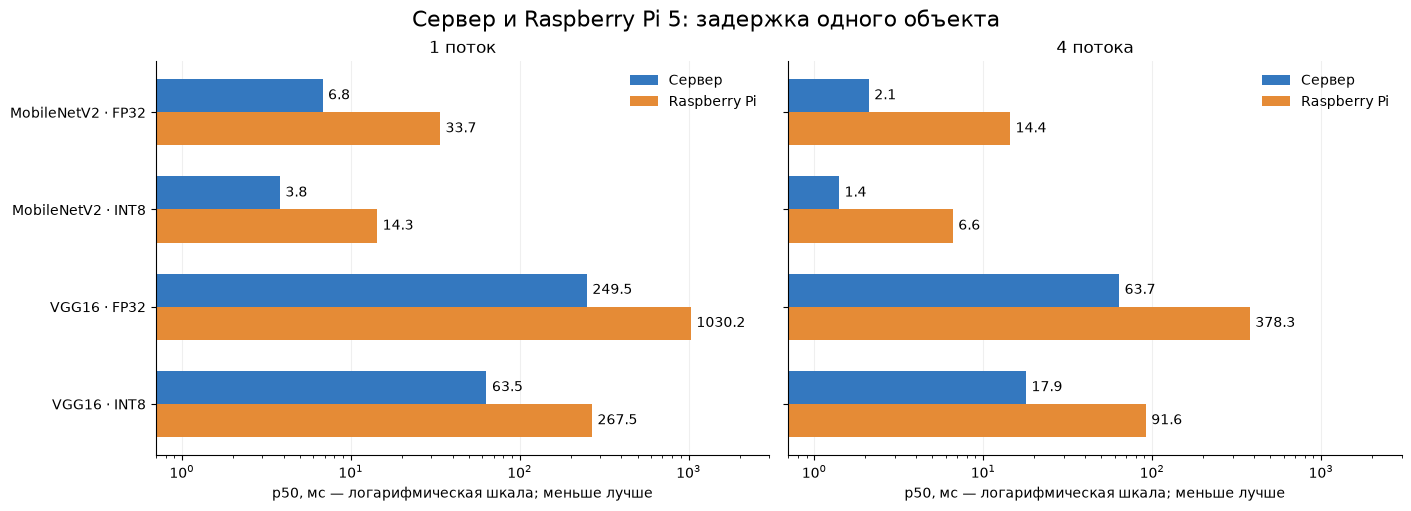

In [15]:
import numpy as np
import matplotlib.pyplot as plt

labels = [
    "MobileNetV2 · FP32",
    "MobileNetV2 · INT8",
    "VGG16 · FP32",
    "VGG16 · INT8",
]

measurements = {
    1: {
        "server": np.array([6.8, 3.8, 249.5, 63.5]),
        "pi": np.array([33.7, 14.3, 1030.2, 267.5]),
    },
    4: {
        "server": np.array([2.1, 1.4, 63.7, 17.9]),
        "pi": np.array([14.4, 6.6, 378.3, 91.6]),
    },
}

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5),
    sharex=True, sharey=True,
    constrained_layout=True,
)
fig.suptitle("Сервер и Raspberry Pi 5: задержка одного объекта", fontsize=16)

y = np.arange(len(labels))
height = 0.34

for ax, threads in zip(axes, [1, 4]):
    values = measurements[threads]
    assert np.all(values["server"] > 0) and np.all(values["pi"] > 0)

    for offset, key, label, color in [
        (-height / 2, "server", "Сервер", "#3478BF"),
        (height / 2, "pi", "Raspberry Pi", "#E58B36"),
    ]:
        bars = ax.barh(
            y + offset, values[key], height=height,
            color=color, label=label,
        )
        ax.bar_label(
            bars,
            labels=[f"{value:.1f}" for value in values[key]],
            padding=4,
        )

    ax.set_title(f"{threads} поток" if threads == 1 else "4 потока")
    ax.set_yticks(y, labels)
    ax.set_xscale("log")
    ax.set_xlim(0.7, 3000)
    ax.set_xlabel("p50, мс — логарифмическая шкала; меньше лучше")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].invert_yaxis()
plt.show()

In [21]:
from torchvision.models import MobileNet_V2_Weights, VGG16_Weights
from IPython.display import Markdown, display

# Для своих моделей считаем параметры напрямую.
# Для стандартных архитектур берём число из метаданных torchvision:
# веса при этом не скачиваются.
parameter_counts = {
    "LeNet": sum(p.numel() for p in lenet.parameters()),
    "MobileNetV3-Large, Flowers102": sum(
        p.numel() for p in mobilenet.parameters()
    ),
    "MobileNetV2, ImageNet": (
        MobileNet_V2_Weights.DEFAULT.meta["num_params"]
    ),
    "VGG16, ImageNet": VGG16_Weights.DEFAULT.meta["num_params"],
}

table = [
    "| Модель | Число параметров |",
    "|---|---:|",
]
for name, count in parameter_counts.items():
    table.append(f"| {name} | {count:,} |")

display(Markdown("\n".join(table)))

ratio = (
    parameter_counts["VGG16, ImageNet"]
    / parameter_counts["MobileNetV2, ImageNet"]
)
print(f"VGG16 / MobileNetV2 по параметрам: {ratio:.2f}×")

(output_dir / "parameter_counts.json").write_text(
    json.dumps(parameter_counts, ensure_ascii=False, indent=2),
    encoding="utf-8",
);

| Модель | Число параметров |
|---|---:|
| LeNet | 44,426 |
| MobileNetV3-Large, Flowers102 | 4,332,694 |
| MobileNetV2, ImageNet | 3,504,872 |
| VGG16, ImageNet | 138,357,544 |

VGG16 / MobileNetV2 по параметрам: 39.48×


#### Вопросы - Ответы

##### Почему отношение числа параметров не равно отношению времени

VGG16 / MobileNetV2 по параметрам: 39.48×

Число параметров характеризует объём весов, но не определяет
количество вычислений напрямую.

В свёрточном слое одни и те же веса используются во многих точках
изображения. Поэтому небольшой по числу параметров слой может выполнять
много операций. Полносвязные слои, наоборот, могут содержать большой
объём весов, каждый из которых используется сравнительно мало.

Кроме того, время зависит от размеров промежуточных тензоров,
обращений к памяти, типов операций и эффективности их реализации.

В наших замерах на Raspberry Pi VGG16 FP32 медленнее MobileNetV2 FP32
в 30.6 раза при одном потоке и в 26.3 раза при четырёх.
Для INT8 отношения другие: 18.7 и 13.9 раза.
Следовательно, перевод числа параметров во время через единый
коэффициент для этих моделей не работает.

In [22]:
import csv
import json
from IPython.display import Markdown, display

# Формат, потоки, сервер p50/p95, Raspberry Pi p50/p95.
measurements = {
    "lenet": [
        ("fp32", 1, 0.032, 0.038, 0.07, 0.08),
        ("fp32", 4, 0.035, 0.041, 0.06, 0.07),
        ("int8", 1, 0.075, 0.081, 0.11, 0.11),
        ("int8", 4, 0.084, 0.090, 0.10, 0.11),
    ],
    "mobilenet": [
        ("fp32", 1, 5.445, 5.483, 31.05, 31.29),
        ("fp32", 4, 2.015, 2.024, 14.27, 14.42),
        ("int8", 1, 19.351, 19.924, 13.90, 13.94),
        ("int8", 4, 13.604, 14.034, 8.00, 8.06),
    ],
    "mobilenet_v2": [
        ("fp32", 1, 6.8, 6.9, 33.7, 33.7),
        ("fp32", 4, 2.1, 2.1, 14.4, 14.6),
        ("int8", 1, 3.8, 3.8, 14.3, 14.4),
        ("int8", 4, 1.4, 1.4, 6.6, 6.6),
    ],
    "vgg16": [
        ("fp32", 1, 249.5, 287.0, 1030.2, 1030.8),
        ("fp32", 4, 63.7, 64.9, 378.3, 395.8),
        ("int8", 1, 63.5, 64.0, 267.5, 267.6),
        ("int8", 4, 17.9, 17.9, 91.6, 93.9),
    ],
}

model_info = {
    "lenet": ("LeNet", 44_426),
    "mobilenet": ("MobileNetV3-Large", 4_332_694),
    "mobilenet_v2": ("MobileNetV2", 3_504_872),
    "vgg16": ("VGG16", 138_357_544),
}

pi_accuracy = {
    "lenet": {"fp32": 64 / 64, "int8": 64 / 64},
    "mobilenet": {"fp32": 43 / 64, "int8": 19 / 64},
}

# Три значения load average из uptime перед соответствующими запусками.
pi_load = {
    "lenet": {
        "fp32": "0.06 / 0.01 / 0.00",
        "int8": "0.01 / 0.01 / 0.00",
    },
    "mobilenet": {
        "fp32": "0.01 / 0.01 / 0.00",
        "int8": "0.09 / 0.02 / 0.01",
    },
    "mobilenet_v2": {
        "fp32": "0.44 / 0.15 / 0.05",
        "int8": "0.44 / 0.15 / 0.05",
    },
    "vgg16": {
        "fp32": "0.48 / 0.16 / 0.06",
        "int8": "0.48 / 0.16 / 0.06",
    },
}

saved_results = json.loads(
    (output_dir / "server_results.json").read_text(encoding="utf-8")
)
server_accuracy = {
    (row["model"], row["format"], row["threads"]): row
    for row in saved_results
}

summary = []

for model_key, measurements_for_model in measurements.items():
    label, parameters = model_info[model_key]
    folder = (
        output_dir if model_key in pi_accuracy
        else output_dir / "reference_models"
    )

    for fmt, threads, server50, server95, pi50, pi95 in measurements_for_model:
        model_path = folder / f"{model_key}_{fmt}.onnx"
        assert model_path.is_file(), f"Не найден файл: {model_path}"
        size_mib = model_path.stat().st_size / 1024**2

        for device, p50, p95 in [
            ("Сервер CPU", server50, server95),
            ("Raspberry Pi 5", pi50, pi95),
        ]:
            accuracy = None
            count = "—"

            if model_key in pi_accuracy:
                if device == "Сервер CPU":
                    saved = server_accuracy[(model_key, fmt, threads)]
                    accuracy = saved["accuracy"]
                    count = saved["validation_count"]
                else:
                    accuracy = pi_accuracy[model_key][fmt]
                    count = 64

            summary.append({
                "Модель": label,
                "Параметров": parameters,
                "Формат": fmt.upper(),
                "Устройство": device,
                "Потоков": threads,
                "N валидации": count,
                "Accuracy, %": (
                    round(accuracy * 100, 2)
                    if accuracy is not None else "—"
                ),
                "p50, мс": p50,
                "p95, мс": p95,
                "Размер, MiB": round(size_mib, 3),
                "Load average": (
                    pi_load[model_key][fmt]
                    if device == "Raspberry Pi 5" else "—"
                ),
            })

assert len(summary) == 32

columns = list(summary[0])
table = [
    "| " + " | ".join(columns) + " |",
    "| " + " | ".join(["---"] * len(columns)) + " |",
]
table.extend(
    "| " + " | ".join(str(row[column]) for column in columns) + " |"
    for row in summary
)
display(Markdown("\n".join(table)))

with (output_dir / "summary.csv").open(
    "w", encoding="utf-8-sig", newline=""
) as file:
    writer = csv.DictWriter(file, fieldnames=columns)
    writer.writeheader()
    writer.writerows(summary)

print("Сводная таблица сохранена:", output_dir / "summary.csv")

| Модель | Параметров | Формат | Устройство | Потоков | N валидации | Accuracy, % | p50, мс | p95, мс | Размер, MiB | Load average |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| LeNet | 44426 | FP32 | Сервер CPU | 1 | 10000 | 98.43 | 0.032 | 0.038 | 0.172 | — |
| LeNet | 44426 | FP32 | Raspberry Pi 5 | 1 | 64 | 100.0 | 0.07 | 0.08 | 0.172 | 0.06 / 0.01 / 0.00 |
| LeNet | 44426 | FP32 | Сервер CPU | 4 | 10000 | 98.43 | 0.035 | 0.041 | 0.172 | — |
| LeNet | 44426 | FP32 | Raspberry Pi 5 | 4 | 64 | 100.0 | 0.06 | 0.07 | 0.172 | 0.06 / 0.01 / 0.00 |
| LeNet | 44426 | INT8 | Сервер CPU | 1 | 10000 | 98.46 | 0.075 | 0.081 | 0.057 | — |
| LeNet | 44426 | INT8 | Raspberry Pi 5 | 1 | 64 | 100.0 | 0.11 | 0.11 | 0.057 | 0.01 / 0.01 / 0.00 |
| LeNet | 44426 | INT8 | Сервер CPU | 4 | 10000 | 98.46 | 0.084 | 0.09 | 0.057 | — |
| LeNet | 44426 | INT8 | Raspberry Pi 5 | 4 | 64 | 100.0 | 0.1 | 0.11 | 0.057 | 0.01 / 0.01 / 0.00 |
| MobileNetV3-Large | 4332694 | FP32 | Сервер CPU | 1 | 1020 | 79.02 | 5.445 | 5.483 | 16.518 | — |
| MobileNetV3-Large | 4332694 | FP32 | Raspberry Pi 5 | 1 | 64 | 67.19 | 31.05 | 31.29 | 16.518 | 0.01 / 0.01 / 0.00 |
| MobileNetV3-Large | 4332694 | FP32 | Сервер CPU | 4 | 1020 | 79.02 | 2.015 | 2.024 | 16.518 | — |
| MobileNetV3-Large | 4332694 | FP32 | Raspberry Pi 5 | 4 | 64 | 67.19 | 14.27 | 14.42 | 16.518 | 0.01 / 0.01 / 0.00 |
| MobileNetV3-Large | 4332694 | INT8 | Сервер CPU | 1 | 1020 | 38.24 | 19.351 | 19.924 | 4.615 | — |
| MobileNetV3-Large | 4332694 | INT8 | Raspberry Pi 5 | 1 | 64 | 29.69 | 13.9 | 13.94 | 4.615 | 0.09 / 0.02 / 0.01 |
| MobileNetV3-Large | 4332694 | INT8 | Сервер CPU | 4 | 1020 | 38.24 | 13.604 | 14.034 | 4.615 | — |
| MobileNetV3-Large | 4332694 | INT8 | Raspberry Pi 5 | 4 | 64 | 29.69 | 8.0 | 8.06 | 4.615 | 0.09 / 0.02 / 0.01 |
| MobileNetV2 | 3504872 | FP32 | Сервер CPU | 1 | — | — | 6.8 | 6.9 | 13.344 | — |
| MobileNetV2 | 3504872 | FP32 | Raspberry Pi 5 | 1 | — | — | 33.7 | 33.7 | 13.344 | 0.44 / 0.15 / 0.05 |
| MobileNetV2 | 3504872 | FP32 | Сервер CPU | 4 | — | — | 2.1 | 2.1 | 13.344 | — |
| MobileNetV2 | 3504872 | FP32 | Raspberry Pi 5 | 4 | — | — | 14.4 | 14.6 | 13.344 | 0.44 / 0.15 / 0.05 |
| MobileNetV2 | 3504872 | INT8 | Сервер CPU | 1 | — | — | 3.8 | 3.8 | 3.715 | — |
| MobileNetV2 | 3504872 | INT8 | Raspberry Pi 5 | 1 | — | — | 14.3 | 14.4 | 3.715 | 0.44 / 0.15 / 0.05 |
| MobileNetV2 | 3504872 | INT8 | Сервер CPU | 4 | — | — | 1.4 | 1.4 | 3.715 | — |
| MobileNetV2 | 3504872 | INT8 | Raspberry Pi 5 | 4 | — | — | 6.6 | 6.6 | 3.715 | 0.44 / 0.15 / 0.05 |
| VGG16 | 138357544 | FP32 | Сервер CPU | 1 | — | — | 249.5 | 287.0 | 527.8 | — |
| VGG16 | 138357544 | FP32 | Raspberry Pi 5 | 1 | — | — | 1030.2 | 1030.8 | 527.8 | 0.48 / 0.16 / 0.06 |
| VGG16 | 138357544 | FP32 | Сервер CPU | 4 | — | — | 63.7 | 64.9 | 527.8 | — |
| VGG16 | 138357544 | FP32 | Raspberry Pi 5 | 4 | — | — | 378.3 | 395.8 | 527.8 | 0.48 / 0.16 / 0.06 |
| VGG16 | 138357544 | INT8 | Сервер CPU | 1 | — | — | 63.5 | 64.0 | 132.184 | — |
| VGG16 | 138357544 | INT8 | Raspberry Pi 5 | 1 | — | — | 267.5 | 267.6 | 132.184 | 0.48 / 0.16 / 0.06 |
| VGG16 | 138357544 | INT8 | Сервер CPU | 4 | — | — | 17.9 | 17.9 | 132.184 | — |
| VGG16 | 138357544 | INT8 | Raspberry Pi 5 | 4 | — | — | 91.6 | 93.9 | 132.184 | 0.48 / 0.16 / 0.06 |

Сводная таблица сохранена: ../Task_3/hw3/summary.csv


##### Ограничения сравнения точности

На сервере точность LeNet рассчитана на 10 000 объектах,
MobileNetV3 — на 1020 объектах. На Raspberry Pi использованы
по 64 объекта каждого набора. Поэтому значения Accuracy между
этими строками нельзя сравнивать напрямую.

На одинаковых 64 входах LeNet FP32, LeNet INT8 и MobileNetV3 FP32
дали полное совпадение предсказаний между устройствами.

Для MobileNetV3 INT8 совпали 43/64 предсказания, для смешанного
варианта — 59/64. Контрольные суммы моделей и входных данных совпали.
Различия относятся к исполнению модели в разных средах:
x86_64 с ONNX Runtime 1.31.0 и aarch64 с ONNX Runtime 1.29.0.
Влияние архитектуры и версии отдельно не исследовалось.

##### Где INT8 дал выигрыш

Для LeNet INT8 оказался медленнее FP32 на обоих устройствах.
Модель очень маленькая, поэтому накладные расходы преобразований
и выполнения отдельных операций могут превышать экономию арифметики.

На Raspberry Pi квантизация MobileNetV3 дала ускорение
в 2.23 раза при одном потоке и в 1.78 раза при четырёх.
Однако на сервере та же INT8-модель оказалась медленнее FP32.
Следовательно, результат зависит не только от числа операций,
но и от их реализации на конкретной платформе.

Наибольший выигрыш на Raspberry Pi получен для VGG16:
ускорение от INT8 составляет 3.85–4.13 раза.
Квантизация уменьшает объём весов и стоимость поддерживаемой
целочисленной арифметики.

Без профилирования нельзя однозначно установить, какая модель
ограничена именно памятью, арифметикой или накладными расходами.
Полученные результаты показывают признаки этих ограничений,
но не разделяют их вклад количественно.

##### Что заменить для запуска LeNet на Pico 2

У LeNet 44 426 параметров. Если каждый параметр хранить одним байтом,
это около 43.4 KiB. Однако это только оценка объёма параметров:
дополнительно нужны масштабы, смещения, описание модели и прошивка.

Чтобы перенести модель на Pico 2, недостаточно скопировать ONNX-файл.
Потребуется:

1. Заменить ONNX Runtime на исполнитель для микроконтроллеров,
   например LiteRT for Microcontrollers.
2. Подготовить модель в поддерживаемом этим исполнителем формате
   и проверить поддержку всех используемых операций.
3. Встроить модель в прошивку как массив байтов во Flash.
4. Выделить в SRAM рабочую память для промежуточных тензоров,
   входа и выхода — tensor arena.
5. Реализовать ту же предобработку MNIST и учесть масштаб и zero point,
   если вход модели становится целочисленным.
6. Проверить точность, расход памяти и время на самом устройстве.

У Pico 2 есть 4 МБ Flash и 520 КБ SRAM. Малый размер весов LeNet
оставляет запас во Flash, но сам по себе не гарантирует,
что вся программа и рабочая память поместятся.

### 5. Детектор с общего стенда

Результаты YOLOv8n на Raspberry Pi 5:

Все запуски выполнены в четыре потока.

| Изображение | Вход | Порог | Кандидатов до NMS | Рамок после NMS | Подготовка, мс | Сеть, мс | Постобработка, мс | Всего, мс |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| bus.jpg | 640×640 | 0.25 | 46 | 5 | 17.7 | 153.4 | 2.5 | 173.6 |
| bus.jpg | 320×320 | 0.25 | 44 | 5 | 9.8 | 34.9 | 0.8 | 45.5 |
| zidane.jpg | 640×640 | 0.25 | 23 | 3 | 15.6 | 151.4 | 2.3 | 169.4 |
| zidane.jpg | 320×320 | 0.25 | 20 | 2 | 9.5 | 34.9 | 0.7 | 45.1 |
| bus.jpg | 640×640 | 0.001 | 658 | 221 | 17.7 | 151.4 | 11.3 | 180.4 |
| zidane.jpg | 640×640 | 0.001 | 864 | 250 | 15.6 | 152.0 | 13.2 | 180.9 |

##### Влияние размера входа

При переходе с 640×640 на 320×320 число пикселей уменьшается в четыре раза.

Время выполнения сети сократилось:
- bus.jpg: 153.4 / 34.9 = **4.40 раза**;
- zidane.jpg: 151.4 / 34.9 = **4.34 раза**.

Полное время обработки уменьшилось меньше:
в **3.82 раза** для bus.jpg и **3.76 раза** для zidane.jpg.
Подготовка и постобработка масштабируются иначе, чем вычисления сети.

На bus.jpg при обоих размерах обнаружены автобус и четыре человека.
Однако уверенность для крайнего слева человека снизилась с 0.43 до 0.27,
то есть приблизилась к порогу 0.25.

На zidane.jpg при входе 640 обнаружены два человека и галстук.
При входе 320 остались только два человека. Уменьшение разрешения
может приводить к потере мелких деталей и небольших объектов.

##### Влияние порога уверенности

При снижении порога с 0.25 до 0.001:

| Изображение | Рост числа кандидатов | Рост времени постобработки |
|---|---:|---:|
| bus.jpg | 658 / 46 = **14.30×** | 11.3 / 2.5 = **4.52×** |
| zidane.jpg | 864 / 23 = **37.57×** | 13.2 / 2.3 = **5.74×** |

Низкий порог пропускает значительно больше кандидатов в NMS.
Алгоритму приходится обрабатывать и сравнивать больше рамок,
поэтому постобработка становится дольше. Время сети почти не изменяется.

Квантизация сети или ускоритель, выполняющий только сеть,
не устраняют затраты отдельной CPU-постобработки.
Для её ускорения нужно менять саму постобработку:
например, ограничивать число кандидатов перед NMS
или использовать более эффективную реализацию.

##### Детекция на собственной фотографии

| Вход | Кандидатов до NMS | Рамок после NMS | Подготовка, мс | Сеть, мс | Постобработка, мс | Всего, мс |
|---|---:|---:|---:|---:|---:|---:|
| 640×640 | 14 | 2 | 99.8 | 150.1 | 2.3 | 252.3 |
| 320×320 | 11 | 2 | 85.7 | 34.5 | 0.7 | 120.9 |

Обе модели обнаружили кота и кровать. При уменьшении входа объекты
из списка детекций не пропали. Уверенность для кота изменилась
с 0.85 до 0.93, для кровати — с 0.58 до 0.36.

Сеть ускорилась в **4.35 раза**, но полное время обработки —
только в **2.09 раза**. Подготовка большого исходного изображения
занимает 85.7–99.8 мс и заметно ограничивает общее ускорение.

Качество положения рамок оценивается визуально:
уверенность модели не является мерой точности координат.

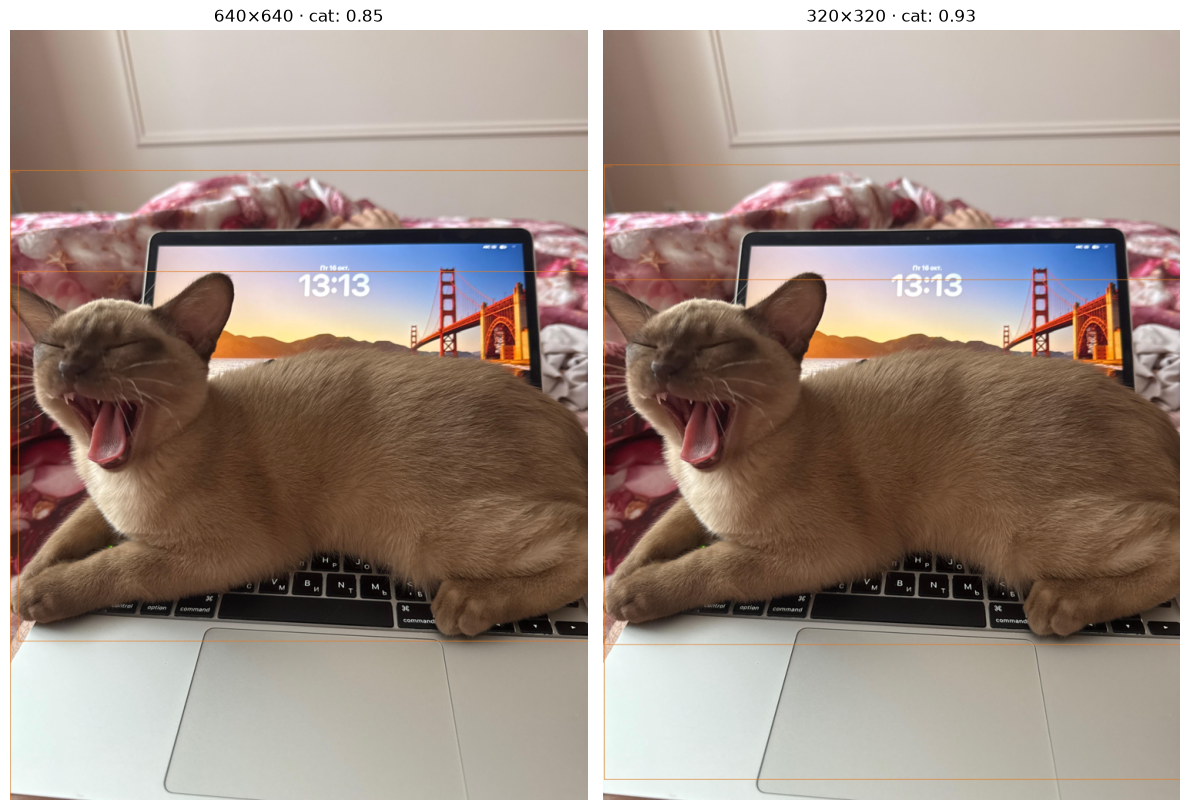

In [20]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 8))

for ax, folder, title in [
    (axes[0], "cat640", "640×640 · cat: 0.85"),
    (axes[1], "cat320", "320×320 · cat: 0.93"),
]:
    path = output_dir / "detection_results" / folder / "camphoto_351212254.JPG"
    with Image.open(path) as image:
        preview = image.convert("RGB")
        preview.thumbnail((1000, 1000))

    ax.imshow(preview)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

вот такая работа из дома...)